# 01 · Inventario de insumos ENDES (2024 y 2025)

**Responsable:** Magno Luque · **Proyecto:** YAWAR (Hackathon FACI 2026, UPCH)

## Para qué sirve este cuaderno
Antes de calcular cualquier cifra, hay que saber **qué datos tenemos y si se pueden unir**. Este cuaderno responde cuatro preguntas:

1. ¿Qué archivos (tablas) descargamos y de qué tamaño son?
2. ¿Las variables que necesitamos existen en **ambos años**?
3. ¿Las tablas se pueden **unir** entre sí sin perder niños?
4. ¿De dónde sacamos la **edad en meses** del niño?

> **Importante:** aquí no hay cifras para el pitch. Los conteos que aparezcan son **sin ponderar** y sirven solo para entender la estructura de los datos. Las cifras ponderadas se calculan en cuadernos posteriores.

## Cómo leerlo
Cada sección tiene tres partes: una explicación en palabras simples, el código y su resultado. Al final hay un resumen de conclusiones y de lo que queda pendiente.

In [1]:
# Preparación. Este cuaderno debe ejecutarse con la carpeta `analisis/` como directorio de trabajo.
import sys
sys.path.insert(0, ".")          # permite importar rutas.py (que está en esta misma carpeta)

import pandas as pd
from rutas import RAW, leer, encabezado, contar_filas, listar_tablas

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
print("Los datos se leen desde:", RAW)

Los datos se leen desde: /sessions/rcw-01c81hrcfa4zkbd2w12wed5c/mnt/Hackaton/endes_raw


## 1. ¿Qué archivos hay?
Cada módulo del INEI trae varias **tablas** (por ejemplo, el módulo 1634 trae REC95, REC43, REC42 y DIT). Contamos cuántas filas (registros) y columnas (variables) tiene cada tabla, y las comparamos entre años.

In [2]:
filas = []
for anio, modulo, tabla, ruta in listar_tablas():
    filas.append((anio, modulo, tabla, contar_filas(ruta), len(encabezado(anio, modulo, tabla))))
inv = pd.DataFrame(filas, columns=["año", "módulo", "tabla", "filas", "columnas"])

comparacion = inv.pivot_table(index=["módulo", "tabla"], columns="año", values=["filas", "columnas"])
print("Tablas y tamaño por año (las que tienen una sola cifra existen en un solo año):\n")
print(comparacion.to_string())
print("\nTotal de tablas: 2024 =", (inv['año'] == 2024).sum(), "| 2025 =", (inv['año'] == 2025).sum())

Tablas y tamaño por año (las que tienen una sola cifra existen en un solo año):

                                  columnas            filas          
año                                   2024   2025      2024      2025
módulo tabla                                                         
1629   RECH0                          44.0   44.0   37390.0   37331.0
       RECH1                          36.0   36.0  135045.0  131929.0
       RECH4                          22.0   22.0  135045.0  131929.0
       RECHM                           8.0    8.0    3002.0    2714.0
1631   REC0111                       104.0  103.0   37117.0   36260.0
       REC91                         343.0  343.0   37117.0   36260.0
1632   RE223132                      149.0  150.0   34252.0   32700.0
       REC21                          34.0   34.0   60693.0   57196.0
1634   DIT                            63.0   63.0   19245.0   18470.0
       REC42                         169.0  169.0   34252.0   32700.0
       RE

## 2. ¿Existen las variables que necesitamos, en los dos años?
Revisamos solo los **nombres de las columnas**. Que el nombre exista en ambos años es necesario, pero **no suficiente** para comparar: todavía hay que confirmar en los diccionarios que la pregunta, los códigos y el periodo de referencia sean iguales (eso queda como pendiente al final).

In [3]:
requeridas = [
    # (grupo, módulo, tabla, variables)
    ("Hierro recibido en 12 meses",      "1634", "REC95",   ["S465DB_A", "S465DB_B", "S465DB_C", "S465DB_D"]),
    ("Hierro tomado en 7 días",          "1634", "REC95",   ["S465EA", "S465EB", "S465EC", "S465ED"]),
    ("Razones de no consumo",            "1634", "REC95",   ["Q465DJ"]),
    ("Tratamiento por anemia",           "1634", "REC95",   ["QI465ED_CC_A", "QI465ED_CC_B", "QI465ED_CC_C", "QI465ED_CC_D"]),
    ("Diseño muestral (mujer)",          "1631", "REC0111", ["V005", "V021", "V022", "V023", "V024", "V025", "V008"]),
    ("Diseño muestral (hogar)",          "1629", "RECH0",   ["HV005", "HV021", "HV022", "HV024", "HV025"]),
    ("Fecha de nacimiento",              "1632", "REC21",   ["B3", "B8"]),
    ("Edad y anemia (niño, individual)", "1638", "REC44",   ["HW1", "HW53", "HW56", "HW57", "HW56A", "HW57A"]),
    ("Edad y anemia (niño, hogar)",      "1638", "RECH6",   ["HC1", "HC57"]),
]

filas = []
for grupo, modulo, tabla, variables in requeridas:
    cols24, cols25 = encabezado(2024, modulo, tabla), encabezado(2025, modulo, tabla)
    for v in variables:
        filas.append((grupo, f"{modulo}/{tabla}", v, "sí" if v in cols24 else "NO", "sí" if v in cols25 else "NO"))
est = pd.DataFrame(filas, columns=["grupo", "módulo/tabla", "variable", "2024", "2025"])
print(est.to_string(index=False))

faltan = est[(est["2024"] == "NO") | (est["2025"] == "NO")]
print("\nVariables que NO están en alguno de los dos años:", "ninguna" if faltan.empty else "")
if not faltan.empty:
    print(faltan.to_string(index=False))

                           grupo módulo/tabla     variable 2024 2025
     Hierro recibido en 12 meses   1634/REC95     S465DB_A   sí   sí
     Hierro recibido en 12 meses   1634/REC95     S465DB_B   sí   sí
     Hierro recibido en 12 meses   1634/REC95     S465DB_C   sí   sí
     Hierro recibido en 12 meses   1634/REC95     S465DB_D   sí   sí
         Hierro tomado en 7 días   1634/REC95       S465EA   sí   sí
         Hierro tomado en 7 días   1634/REC95       S465EB   sí   sí
         Hierro tomado en 7 días   1634/REC95       S465EC   sí   sí
         Hierro tomado en 7 días   1634/REC95       S465ED   sí   sí
           Razones de no consumo   1634/REC95       Q465DJ   sí   sí
          Tratamiento por anemia   1634/REC95 QI465ED_CC_A   sí   sí
          Tratamiento por anemia   1634/REC95 QI465ED_CC_B   sí   sí
          Tratamiento por anemia   1634/REC95 QI465ED_CC_C   sí   sí
          Tratamiento por anemia   1634/REC95 QI465ED_CC_D   sí   sí
         Diseño muestral (mujer) 1

### Variables que cambian de un año a otro
El nombre existe en ambos años para todo lo que necesitamos. Aun así, algunas tablas tienen distinto número de columnas (se vio en la sección 1). Listamos qué columnas hay en un año y no en el otro, para saber si afectan algo.

In [4]:
hay_diferencias = False
for anio, modulo, tabla, ruta in listar_tablas():
    if anio != 2024:
        continue
    try:
        c24, c25 = encabezado(2024, modulo, tabla), encabezado(2025, modulo, tabla)
    except FileNotFoundError:
        continue
    solo25 = [c for c in c25 if c not in c24]
    solo24 = [c for c in c24 if c not in c25]
    if solo25 or solo24:
        hay_diferencias = True
        print(f"{modulo}/{tabla}")
        print("   solo en 2025:", solo25 if solo25 else "-")
        print("   solo en 2024:", solo24 if solo24 else "-")
if not hay_diferencias:
    print("Sin diferencias de columnas.")

1631/REC0111
   solo en 2025: -
   solo en 2024: ['mujeres12a49']
1632/RE223132
   solo en 2025: ['QI616AD']
   solo en 2024: -
1634/REC95
   solo en 2025: ['QI461G', 'QI461H', 'QI461I', 'QI461J', 'S45V', 'S45VD', 'S45VM', 'S45VY', 'QIEDAD_GEST', 'QI456_1A', 'QI456_1B', 'QI456_1X', 'QI466E_1A', 'QI466E_1B', 'QI466E_1X']
   solo en 2024: -
1641/Programas Sociales x Hogar
   solo en 2025: ['QH100B']
   solo en 2024: -


## 3. ¿Se pueden unir las tablas?
Cada tabla identifica a sus registros con una **llave**:

| Tabla | Qué es una fila | Llave |
|---|---|---|
| REC95 (hierro) | un niño menor de 5 años | `CASEID` (la madre) + `IDX95` (el niño) |
| REC44 (edad y anemia) | un niño | `CASEID` + `HWIDX` |
| REC21 (nacimientos) | un nacimiento | `CASEID` + `BIDX` |
| REC0111 (diseño muestral) | una mujer | `CASEID` |

Unir tablas sin cuidado puede **perder niños o duplicarlos**. Por eso medimos, para cada unión, cuántos registros no encuentran pareja. Los índices se convierten a número para que `1` y `01` cuenten como lo mismo.

In [5]:
def con_llave(df, caseid, idx=None):
    # Devuelve el DataFrame con una columna 'llave' (texto) para comparar tablas.
    df = df.copy()
    if idx is None:
        df["llave"] = df[caseid]
    else:
        df["llave"] = df[caseid] + "|" + pd.to_numeric(df[idx]).astype("Int64").astype(str)
    return df

resumen = []
for anio in (2024, 2025):
    r95  = con_llave(leer(anio, "1634", "REC95",   ["CASEID", "IDX95"]),  "CASEID", "IDX95")
    r44  = con_llave(leer(anio, "1638", "REC44",   ["CASEID", "HWIDX"]),  "CASEID", "HWIDX")
    r21  = con_llave(leer(anio, "1632", "REC21",   ["CASEID", "BIDX"]),   "CASEID", "BIDX")
    r011 = con_llave(leer(anio, "1631", "REC0111", ["CASEID"]),           "CASEID")

    resumen.append((anio, "filas en REC95 (niños)", len(r95)))
    resumen.append((anio, "filas en REC44", len(r44)))
    resumen.append((anio, "REC95: llaves repetidas (debe ser 0)", int(r95["llave"].duplicated().sum())))
    resumen.append((anio, "REC95 sin pareja en REC44", int((~r95["llave"].isin(r44["llave"])).sum())))
    resumen.append((anio, "REC44 sin pareja en REC95", int((~r44["llave"].isin(r95["llave"])).sum())))
    resumen.append((anio, "REC95 sin pareja en REC21 (nacimientos)", int((~r95["llave"].isin(r21["llave"])).sum())))
    resumen.append((anio, "REC95 sin pareja en REC0111 (diseño)", int((~r95["CASEID"].isin(r011["llave"])).sum())))
    resumen.append((anio, "REC0111: mujeres repetidas (debe ser 0)", int(r011["llave"].duplicated().sum())))

res = pd.DataFrame(resumen, columns=["año", "comprobación", "resultado"]).pivot(index="comprobación", columns="año", values="resultado")
print(res.to_string())
print("\nLectura: 0 en 'sin pareja' significa que todo niño de REC95 se encuentra en esa otra tabla.")

año                                       2024   2025
comprobación                                         
REC0111: mujeres repetidas (debe ser 0)      0      0
REC44 sin pareja en REC95                    0      0
REC95 sin pareja en REC0111 (diseño)         0      0
REC95 sin pareja en REC21 (nacimientos)      0      0
REC95 sin pareja en REC44                    0      0
REC95: llaves repetidas (debe ser 0)         0      0
filas en REC44                           19751  18841
filas en REC95 (niños)                   19751  18841

Lectura: 0 en 'sin pareja' significa que todo niño de REC95 se encuentra en esa otra tabla.


## 4. Edad del niño en meses
El plan del equipo pide la edad **desde los 6 meses** (hoy solo se tenía desde los 9). Hay dos caminos posibles:

- **Camino A (directo):** la variable `HW1` de la tabla REC44, "Edad en meses", con rango 0 a 59 según el diccionario.
- **Camino B (calculado):** fecha de la entrevista (`V008`) menos fecha de nacimiento (`B3`). Ambas están en formato CMC (cuenta de meses desde enero de 1900), así que la resta da meses.

Usamos el camino B como **verificación** del A: si coinciden, confiamos en `HW1`.

In [6]:
resultados = []
bandas = {}
for anio in (2024, 2025):
    r95  = con_llave(leer(anio, "1634", "REC95", ["CASEID", "IDX95"]), "CASEID", "IDX95")
    r44  = con_llave(leer(anio, "1638", "REC44", ["CASEID", "HWIDX", "HW1"]), "CASEID", "HWIDX")[["llave", "HW1"]]
    r21  = con_llave(leer(anio, "1632", "REC21", ["CASEID", "BIDX", "B3"]), "CASEID", "BIDX")[["llave", "B3"]]
    r011 = leer(anio, "1631", "REC0111", ["CASEID", "V008"]).rename(columns={"CASEID": "CASEID_m"})

    d = r95.merge(r44, on="llave", how="left").merge(r21, on="llave", how="left")
    d = d.merge(r011, left_on="CASEID", right_on="CASEID_m", how="left")
    for c in ("HW1", "B3", "V008"):
        d[c] = pd.to_numeric(d[c], errors="coerce")
    d["edad_calculada"] = d["V008"] - d["B3"]
    dif = (d["edad_calculada"] - d["HW1"]).abs()

    resultados.append((anio, "niños en REC95", len(d)))
    resultados.append((anio, "con HW1 (edad directa)", int(d["HW1"].notna().sum())))
    resultados.append((anio, "con edad calculada (V008 - B3)", int(d["edad_calculada"].notna().sum())))
    resultados.append((anio, "edad directa = calculada", int((dif == 0).sum())))
    resultados.append((anio, "difieren en 1 mes", int((dif == 1).sum())))
    resultados.append((anio, "difieren en más de 1 mes", int((dif > 1).sum())))
    resultados.append((anio, "HW1 mínimo", int(d["HW1"].min())))
    resultados.append((anio, "HW1 máximo", int(d["HW1"].max())))
    d["banda_edad"] = pd.cut(d["HW1"], [-1, 5, 8, 35, 59], labels=["0-5", "6-8", "9-35", "36-59"])
    bandas[anio] = d["banda_edad"].value_counts().reindex(["0-5", "6-8", "9-35", "36-59"])

print(pd.DataFrame(resultados, columns=["año", "comprobación", "resultado"]).pivot(index="comprobación", columns="año", values="resultado").to_string())
print("\nNiños por banda de edad en meses (según HW1, SIN ponderar):")
print(pd.DataFrame(bandas).to_string())

año                              2024   2025
comprobación                                
HW1 máximo                         59     59
HW1 mínimo                          0      0
con HW1 (edad directa)          19234  18289
con edad calculada (V008 - B3)  19751  18841
difieren en 1 mes                 324    264
difieren en más de 1 mes           59     33
edad directa = calculada        18851  17992
niños en REC95                  19751  18841

Niños por banda de edad en meses (según HW1, SIN ponderar):
            2024  2025
banda_edad            
0-5         1444  1262
6-8          993   992
9-35        8975  8324
36-59       7822  7711


## 5. ¿Cómo vienen codificadas las preguntas de hierro?
Miramos, lado a lado, qué códigos aparecen en cada año. Según el diccionario: `1` = sí, `2` = no, `8` = no sabe, y vacío = la pregunta no se hizo a ese niño. **Los vacíos no son "no"**: hay que entender a quién no se le preguntó antes de definir el denominador.

### Cuidado: las letras A–D no significan lo mismo en las dos preguntas
Leyendo el diccionario de REC95, las presentaciones de hierro **no están en el mismo orden** en la pregunta de "recibió" (12 meses) y en la de "tomó" (7 días). Si se emparejaran por la letra (A con A, B con B...), se compararían presentaciones distintas.

| Presentación | Recibió en 12 meses | Tomó en 7 días |
|---|---|---|
| Hierro en jarabe | `S465DB_A` | `S465EA` |
| Hierro en gotas | `S465DB_B` | `S465EC` |
| Hierro en polvo (micronutrientes: chispitas, estrellitas, Nutrimix) | `S465DB_C` | `S465EB` |
| Otra presentación | `S465DB_D` | `S465ED` |

Esta tabla está transcrita del diccionario de 2024 y del de 2025 (la redacción es la misma en ambos años). Conviene que Jose la revise antes de armar la etiqueta del modelo.

In [7]:
variables = ["S465DB_A", "S465DB_B", "S465DB_C", "S465DB_D", "S465EA", "S465EB", "S465EC", "S465ED"]
cols = ["CASEID"] + variables
datos = {a: leer(a, "1634", "REC95", cols) for a in (2024, 2025)}

for v in variables:
    t = pd.concat({a: datos[a][v].fillna("(vacío)").value_counts() for a in (2024, 2025)}, axis=1).fillna(0).astype(int)
    print(f"--- {v} ---")
    print(t.to_string(), "\n")

--- S465DB_A ---
           2024   2025
S465DB_A              
2         11421  10462
1          7241   7477
(vacío)    1088    897
8             1      5 

--- S465DB_B ---
           2024   2025
S465DB_B              
2         13775  13451
1          4882   4486
(vacío)    1088    897
8             6      7 

--- S465DB_C ---
           2024   2025
S465DB_C              
2         16829  15793
1          1825   2143
(vacío)    1088    897
8             9      8 

--- S465DB_D ---
           2024   2025
S465DB_D              
2         18624  17925
(vacío)    1088    897
1            33      9
8             6     10 

--- S465EA ---
          2024   2025
S465EA               
2        16425  15640
1         2232   2300
(vacío)   1088    897
8            6      4 

--- S465EB ---
          2024   2025
S465EB               
2        18390  17300
(vacío)   1088    897
1          268    640
8            5      4 

--- S465EC ---
          2024   2025
S465EC               
2        16633 

### ¿A quién no se le preguntó? (los vacíos, por edad)
Cruzamos los vacíos de `S465DB_A` ("recibió hierro") con la edad del niño, para saber si los vacíos corresponden a bebés muy pequeños u a otra situación. Es una exploración **sin ponderar**.

In [8]:
for anio in (2024, 2025):
    r95 = con_llave(leer(anio, "1634", "REC95", ["CASEID", "IDX95", "S465DB_A"]), "CASEID", "IDX95")
    r44 = con_llave(leer(anio, "1638", "REC44", ["CASEID", "HWIDX", "HW1"]), "CASEID", "HWIDX")[["llave", "HW1"]]
    d = r95.merge(r44, on="llave", how="left")
    d["edad_m"] = pd.to_numeric(d["HW1"], errors="coerce")
    d["banda"] = pd.cut(d["edad_m"], [-1, 5, 8, 35, 59], labels=["0-5", "6-8", "9-35", "36-59"])
    d["recibió (S465DB_A)"] = d["S465DB_A"].fillna("(vacío)")
    print(f"=== {anio}: niños por edad y respuesta a 'recibió hierro' (sin ponderar) ===")
    print(pd.crosstab(d["banda"], d["recibió (S465DB_A)"]).to_string(), "\n")

=== 2024: niños por edad y respuesta a 'recibió hierro' (sin ponderar) ===
recibió (S465DB_A)  (vacío)     1     2  8
banda                                     
0-5                     805    19   620  0
6-8                       1   212   780  0
9-35                     13  4195  4766  1
36-59                    12  2749  5061  0 

=== 2025: niños por edad y respuesta a 'recibió hierro' (sin ponderar) ===
recibió (S465DB_A)  (vacío)     1     2  8
banda                                     
0-5                     682    29   551  0
6-8                       1   159   832  0
9-35                      2  4066  4254  2
36-59                     6  3119  4583  3 



## 6. ¿Se repiten conglomerados entre 2024 y 2025?
La ficha técnica de 2025 dice que los conglomerados con la **misma numeración** en 2024 y 2025 son "paneles", es decir, la misma zona visitada dos veces. Eso importa para validar el modelo: si entrenamos con 2024 y evaluamos con 2025 pero una parte de los niños viene de las mismas zonas, 2025 **no es del todo un año "no visto"**. Medimos cuánto se repite, por conglomerado (`V021`) y por niño.

In [9]:
c = {}
for anio in (2024, 2025):
    r95 = leer(anio, "1634", "REC95", ["CASEID"])
    r011 = leer(anio, "1631", "REC0111", ["CASEID", "V021"])
    c[anio] = r95.merge(r011, on="CASEID", how="left")

cong24, cong25 = set(c[2024]["V021"].dropna()), set(c[2025]["V021"].dropna())
comunes = cong24 & cong25
print("Conglomerados con niños menores de 5 en 2024:", len(cong24))
print("Conglomerados con niños menores de 5 en 2025:", len(cong25))
print("Conglomerados que aparecen en ambos años:   ", len(comunes), f"({len(comunes)/len(cong25):.0%} de los de 2025)")
en_comun_25 = c[2025]["V021"].isin(comunes).sum()
print("Niños de 2025 que viven en un conglomerado que también está en 2024:", en_comun_25, f"de {len(c[2025])} ({en_comun_25/len(c[2025]):.0%})")
print("\nOjo: que el número coincida indica un panel según la ficha técnica; no se verificó vivienda por vivienda.")

Conglomerados con niños menores de 5 en 2024: 3228
Conglomerados con niños menores de 5 en 2025: 3207
Conglomerados que aparecen en ambos años:    2117 (66% de los de 2025)
Niños de 2025 que viven en un conglomerado que también está en 2024: 12124 de 18841 (64%)

Ojo: que el número coincida indica un panel según la ficha técnica; no se verificó vivienda por vivienda.


## Gráficos de este cuaderno
Dos vistas rápidas, **sin ponderar**, de lo que vimos en las tablas: (izquierda) cuántos niños hay en cada edad en meses, y (derecha) en qué edades la pregunta "¿recibió hierro?" (`S465DB_A`) viene **vacía**. Los vacíos se concentran en los más pequeños: por eso el universo de trabajo parte de los 6 meses.

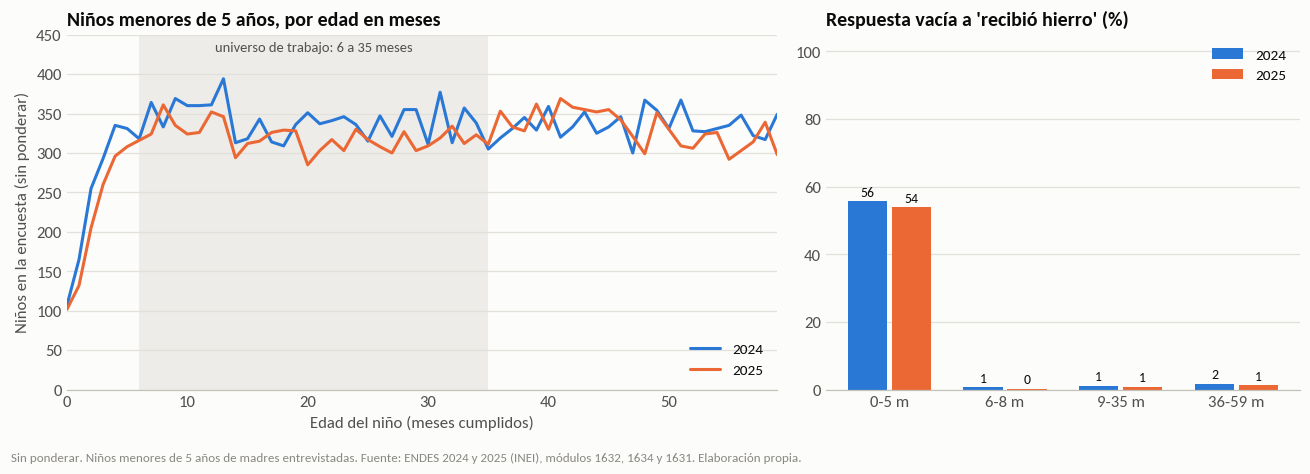

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import graficos as g

edad_por_mes, vacio_por_banda = {}, {}
BANDAS_01 = ["0-5", "6-8", "9-35", "36-59"]
for anio in (2024, 2025):
    r95 = con_llave(leer(anio, "1634", "REC95", ["CASEID", "IDX95", "S465DB_A"]), "CASEID", "IDX95")
    r21 = con_llave(leer(anio, "1632", "REC21", ["CASEID", "BIDX", "B3"]), "CASEID", "BIDX")[["llave", "B3"]]
    r011 = leer(anio, "1631", "REC0111", ["CASEID", "V008"])
    d = r95.merge(r21, on="llave", how="left").merge(r011, on="CASEID", how="left")
    d["edad"] = pd.to_numeric(d["V008"]) - pd.to_numeric(d["B3"])
    edad_por_mes[anio] = d["edad"].value_counts().reindex(range(60)).fillna(0)
    d["banda"] = pd.cut(d["edad"], [-1, 5, 8, 35, 59], labels=BANDAS_01)
    vacio_por_banda[anio] = d["S465DB_A"].isna().groupby(d["banda"], observed=False).mean().reindex(BANDAS_01) * 100

fig, axs = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axs[0]
ax.axvspan(6, 35, color=g.REJILLA, alpha=0.55, linewidth=0, zorder=0)
for anio in (2024, 2025):
    ax.plot(edad_por_mes[anio].index, edad_por_mes[anio].values, color=g.COLOR_ANIO[anio], linewidth=2, solid_capstyle="round", label=str(anio))
ax.set_ylim(0, 450)
ax.text(20.5, 442, "universo de trabajo: 6 a 35 meses", ha="center", va="top", fontsize=9.5, color=g.TINTA2)
ax.set_xlabel("Edad del niño (meses cumplidos)")
ax.set_ylabel("Niños en la encuesta (sin ponderar)")
ax.set_title("Niños menores de 5 años, por edad en meses")
ax.set_xlim(0, 59)
g.rejilla(ax, "y")
ax.legend(loc="lower right")

ax = axs[1]
x = np.arange(len(BANDAS_01))
for anio, desp in ((2024, -0.19), (2025, 0.19)):
    v = vacio_por_banda[anio].values
    ax.bar(x + desp, v, width=0.34, color=g.COLOR_ANIO[anio], label=str(anio), zorder=2)
    for xi, vi in zip(x + desp, v):
        ax.text(xi, vi + 1.5, f"{vi:.0f}", ha="center", fontsize=9, color=g.TINTA)
ax.set_xticks(x)
ax.set_xticklabels([b + " m" for b in BANDAS_01])
ax.set_ylim(0, 105)
ax.set_title("Respuesta vacía a 'recibió hierro' (%)")
g.rejilla(ax, "y")
ax.legend(loc="upper right")
g.pie(fig, "Sin ponderar. Niños menores de 5 años de madres entrevistadas. Fuente: ENDES 2024 y 2025 (INEI), módulos 1632, 1634 y 1631. Elaboración propia.")
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

## 7. Conclusiones y pendientes

### Lo que quedó confirmado
1. **Los insumos están completos:** 23 tablas de 2024 y 24 de 2025. La tabla extra de 2025 es `PS_CUNAMAS_VISITA` (programas sociales; no entra en el análisis principal).
2. **Las variables que necesitamos existen en ambos años** con el mismo nombre: hierro recibido y tomado, razones de no consumo, diseño muestral, fecha de nacimiento, edad y anemia.
3. **Las uniones funcionan sin perder niños:** al unir REC95 con REC44, REC21 y REC0111 no queda ningún niño sin pareja y no hay llaves repetidas, en 2024 ni en 2025.
4. **La anemia se puede ponderar con el mismo diseño que el hierro.** REC44 trae la hemoglobina y la anemia con la misma llave (`CASEID` + índice del niño), así que se une a `V005` de REC0111. No dependemos de `RECH6` ni del módulo 1629 para eso (este último queda como verificación cruzada).
5. **La edad en meses se puede obtener para todos los niños.** La edad calculada (`V008 − B3`) existe para el 100 % de los niños. La edad directa (`HW1`) falta en 517 niños (2024) y 552 (2025), y donde existe coincide con la calculada en el 98,0 % (2024) y 98,4 % (2025) de los casos.
6. **Los vacíos en las preguntas de hierro corresponden, en su gran mayoría, a menores de 6 meses** (entre los vacíos con edad conocida: 805 de 831 en 2024 y 682 de 691 en 2025). Esto respalda empezar la cohorte a los 6 meses y no a los 9.

### Hallazgos que cambian cómo trabajamos
- **Las letras A–D no se corresponden entre las preguntas de "recibió" y "tomó"** (ver tabla de la sección 5). Emparejarlas por letra sería un error. El plan del equipo y el README de datos las nombran como "A a D" sin esta salvedad.
- **Entre 64 % de los niños de 2025 vive en zonas que también están en 2024** (2 117 conglomerados en común). Entrenar con 2024 y evaluar con 2025 **no es una validación en un año completamente no visto**. Esto afecta la decisión de Jose y mía sobre validar por año o por regiones.
- **La anemia tiene dos definiciones en los datos:** `HW57` (RM 363-2022-MINSA) y `HW57A` (nueva directriz OMS 2024 / RM 251-2024-MINSA). La conclusión de que "la anemia casi no bajó" puede depender de cuál se use. Hay que elegir una y justificarla.
- **Un cambio llamativo (sin ponderar):** los niños con "sí tomó hierro en polvo en los últimos 7 días" (`S465EB`) pasan de 268 a 640, y "recibió polvo" (`S465DB_C`) de 1 825 a 2 143. La redacción de las preguntas es igual en los dos diccionarios, así que no parece un cambio de pregunta, pero conviene entender el cambio antes de comparar años.
- **REC95 de 2025 trae 15 variables nuevas** (`QI461G` a `QI461J`, `S45V*`, `QIEDAD_GEST`, `QI456_1*`, `QI466E_1*`). Ninguna es de las que usamos.

### Pendientes (no se pueden cerrar con este cuaderno)
| Pendiente | Quién | Cómo se cierra |
|---|---|---|
| Elegir edad calculada o `HW1` como edad oficial | Magno | Propuesta: usar la calculada (completa) y `HW1` como control |
| Confirmar la letra de cada presentación de hierro | Jose y Magno | Revisar la tabla de la sección 5 con el diccionario |
| Validar con 2024 o por regiones | Jose y Magno | Con el 64 % de niños en zonas repetidas, decidir y dejarlo anotado en `docs/` |
| Qué definición de anemia usar (`HW57` o `HW57A`) | Magno, con Camilla | Consultar al asesor de salud cuál es la vigente |
| Por qué sube el consumo de polvo entre años | Magno | Revisar con cifras ponderadas (cuaderno 04) |
| Comprobar que `V005` se divide entre 1 000 000 | Magno | Leer la ficha técnica; se verifica al ponderar (cuaderno 04) |
| Fijar la cohorte | Jose y Magno | Con los vacíos y la edad ya entendidos, decidir los criterios |

**Siguiente cuaderno:** `02_comparacion_2024_2025`, que compara año contra año la estructura de edad, área y región y las tasas básicas, antes de unir y limpiar.